# 03 · Análisis exploratorio (EDA)
**Proyecto Integrador ML2 — Segunda entrega · Predicción de la TRM**

**Para qué sirve este EDA.** No es un paso descriptivo: responde, **antes de entrenar un solo modelo**, las preguntas de las que depende todo el proyecto. Cada sección plantea una pregunta, la responde con evidencia y termina en una **consecuencia para el modelado** o en una **hipótesis** que se contrasta después con los resultados (notebooks 05 y 06). Así, lo que salga de los modelos se podrá explicar y no solo reportar.

| # | Pregunta | Qué decide o anticipa |
|---|---|---|
| E1 | ¿Por qué no modelar el nivel de la TRM? | El objetivo en retornos |
| E2 | ¿Cómo son los retornos diarios? ¿Hay días que dominan el error? | Qué métricas reportar |
| E3 | ¿La dificultad cambia con el tiempo? | Cuánto variará el error entre cortes |
| E4 | ¿Hay memoria en la TRM? ¿Sirven los rezagos 1, 5 y 10 de la Entrega 1? | La línea base |
| E5 | ¿Cada variable se relaciona con el objetivo como dice la teoría? | La interpretación esperada |
| E6 | ¿Esas relaciones son estables en el tiempo? | Si las macro aportarán de forma confiable |
| E7 | ¿Qué papel tiene el diferencial de tasas? | La lectura de su efecto |
| E8 | ¿Las variables se repiten entre sí? | La lectura de las importancias |
| E9 | ¿Hay relaciones no lineales que el boosting pueda aprovechar? | Si el boosting puede ganarle al lineal |
| E10 | ¿Cambia todo esto por régimen histórico? | La explicación de los errores |

**Regla anti-fuga del EDA:** todo se calcula con los **4.320 días de desarrollo** (hasta el 1 de marzo de 2022). El test no se abre.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LinearRegression

from src import config as cfg
from src.eda import (pruebas_estacionariedad, resumen_distribucion, concentracion_error, acf_con_banda,
                     correlacion_con_ic, medias_por_decil, vif)
from src.validacion import cortes_walk_forward, tabla_cortes
from src.graficos import estilo, guardar_figura, guardar_tabla, COLORES

estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
datos = pd.read_csv(cfg.DATA_PROC / "dataset.csv", parse_dates=["fecha"])
particion = json.loads((cfg.DATA_PROC / "particion.json").read_text())
dev = datos[datos["muestra"] == "desarrollo"].reset_index(drop=True)      # SOLO desarrollo
assert dev["fecha"].max() <= pd.Timestamp(particion["desarrollo_hasta"])
y = dev["y"]

limpias = pd.read_csv(cfg.DATA_PROC / "series_limpias.csv", parse_dates=["fecha"])
limpias = limpias[limpias["fecha"] <= dev["fecha"].max()]                 # niveles, también solo desarrollo
nivel = lambda n: limpias.loc[limpias["serie"] == n].set_index("fecha")["valor"]
print(f"Desarrollo: {len(dev):,} días, {dev['fecha'].min().date()} a {dev['fecha'].max().date()}")

Desarrollo: 4,320 días, 2003-12-17 a 2022-03-01


## E1. ¿Por qué no modelar el nivel de la TRM?
Se aplican dos pruebas con hipótesis opuestas, para no depender de una sola: **ADF** (H0: la serie tiene raíz unitaria, es decir, no es estacionaria) y **KPSS** (H0: la serie es estacionaria). Una serie se declara estacionaria solo si las dos coinciden.

In [2]:
series_e1 = {
    "TRM (nivel)": nivel("TRM"), "TRM (retorno = y)": y,
    "Brent (nivel)": nivel("Brent"), "Brent (retorno)": dev["r_brent"],
    "DXY (nivel)": nivel("DXY"), "DXY (retorno)": dev["r_dxy"],
    "Diferencial TPM − DFF (nivel)": dev["dif_tasas"], "Diferencial (cambio diario)": dev["dif_tasas"].diff(),
}
e1 = pruebas_estacionariedad(series_e1)
guardar_tabla(e1, "tabE1_estacionariedad")
display(e1)
print(f"Rango de la TRM en desarrollo: {nivel('TRM').min():,.0f} a {nivel('TRM').max():,.0f} pesos; "
      f"máximo hasta mediados de 2018: {nivel('TRM')[:'2018-07-17'].max():,.0f}.")

,p_ADF,p_KPSS,conclusion
serie,,,
TRM (nivel),0.9234,0.0100,no estacionaria
TRM (retorno = y),0.0000,0.0713,estacionaria
Brent (nivel),0.2653,0.0100,no estacionaria
Brent (retorno),0.0000,0.1000,estacionaria
DXY (nivel),0.5165,0.0100,no estacionaria
DXY (retorno),0.0000,0.1000,estacionaria
Diferencial TPM − DFF (nivel),0.0973,0.0100,no estacionaria
Diferencial (cambio diario),0.0000,0.1000,estacionaria


Rango de la TRM en desarrollo: 1,652 a 4,154 pesos; máximo hasta mediados de 2018: 3,435.


**Conclusión E1.** Los **niveles** de la TRM, el Brent, el DXY y el diferencial **no son estacionarios** (ADF no rechaza y KPSS sí rechaza). Sus **retornos** o cambios **sí lo son**, y las dos pruebas coinciden en todas las series. Un modelo entrenado sobre niveles aprende relaciones atadas al rango que vio: en desarrollo la TRM se movió entre 1.652 y 4.154 pesos, pero el rango cambia con el tiempo: hasta mediados de 2018 nunca pasó de 3.435, y en 2021 llegó a 4.154.

**→ Consecuencia:** modelar el **retorno** no es una preferencia, es lo que exigen los datos. Es la base estadística de la adaptación, y el notebook 04 muestra qué pasa si se ignora.

## E2. ¿Cómo son los retornos diarios? ¿Hay días que dominan el error?
Si unos pocos días extremos concentran casi todo el error cuadrático, el RMSE (métrica principal de la Entrega 1) dependerá de ellos. Eso define cómo leer las métricas.

,y (retorno de la TRM)
n,"4,320.0000"
media,0.0001
desv_est,0.0075
volatilidad_anual_pct,11.9428
asimetria,0.2002
curtosis_exceso,5.5608
pct_dias_mas_4sd,0.5324
veces_lo_esperado_si_normal,84.0522
p_jarque_bera,0.0000


Del error cuadrático de predecir 'sin cambio' (ŷ = 0):


,pct_del_error_cuadratico
top_1pct_dias,21.2486
top_5pct_dias,46.1084


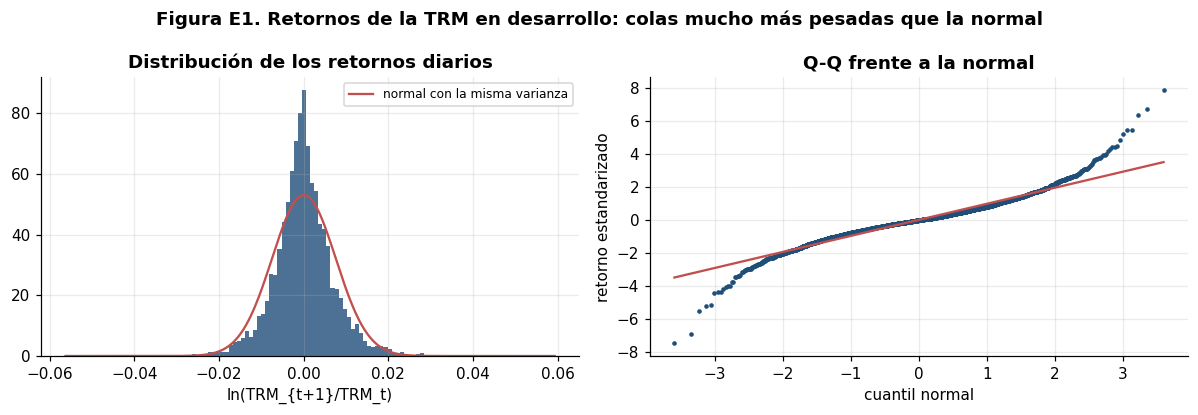

In [3]:
e2 = resumen_distribucion(y).to_frame("y (retorno de la TRM)")
conc = concentracion_error(y)
guardar_tabla(e2, "tabE2_distribucion")
display(e2)
print("Del error cuadrático de predecir 'sin cambio' (ŷ = 0):")
display(conc.to_frame())

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
ejes[0].hist(y, bins=120, density=True, color=COLORES[0], alpha=0.8)
xs = np.linspace(y.min(), y.max(), 400)
ejes[0].plot(xs, stats.norm.pdf(xs, y.mean(), y.std()), color=COLORES[1], lw=1.5, label="normal con la misma varianza")
ejes[0].set(title="Distribución de los retornos diarios", xlabel="ln(TRM_{t+1}/TRM_t)"); ejes[0].legend(fontsize=8)
stats.probplot((y - y.mean()) / y.std(), dist="norm", plot=ejes[1])
ejes[1].get_lines()[0].set(markersize=2, color=COLORES[0]); ejes[1].get_lines()[1].set(color=COLORES[1])
ejes[1].set(title="Q-Q frente a la normal", xlabel="cuantil normal", ylabel="retorno estandarizado")
fig.suptitle("Figura E1. Retornos de la TRM en desarrollo: colas mucho más pesadas que la normal", fontweight="bold")
fig.tight_layout(); guardar_figura(fig, "figE1_distribucion"); plt.show()

**Conclusión E2.** El retorno diario de la TRM tiene media prácticamente nula y una volatilidad del **11,9 % anual**, pero **colas muy pesadas**: curtosis de exceso de 5,6. Los días con movimientos de más de 4 desviaciones estándar son **84 veces** más frecuentes de lo que predice una normal, y Jarque-Bera rechaza la normalidad (p < 0,001). En consecuencia, **el 1 % de los días más extremos genera el 21 % del error cuadrático** de predecir "sin cambio", y el 5 % genera el 46 %.

**→ Consecuencia:** el RMSE, métrica principal de la Entrega 1, va a depender de unos pocos días extremos. Por eso se reporta junto al **MAE**, que refleja el error típico. Si un modelo gana en RMSE y no en MAE, la ganancia viene de esos pocos días, y viceversa.

## E3. ¿La dificultad de predecir cambia con el tiempo?
Se mide la volatilidad móvil (60 días) y se compara la autocorrelación de los retornos con la de los retornos al cuadrado: si la segunda es mucho mayor, la volatilidad **se agrupa** (días turbulentos siguen a días turbulentos). Además se calcula la volatilidad de cada uno de los **5 periodos de validación del walk-forward** que se usarán en el notebook 05, para anticipar cuánto variará el error entre cortes.

,retornos,retornos al cuadrado
rezago,,
1,0.1655,0.2438
5,-0.0096,0.2120
10,0.0297,0.1187


,entrena_desde,entrena_hasta,filas_entrenamiento,valida_desde,valida_hasta,filas_validacion,volatilidad_anual_pct,rmse_sin_cambio_pesos
corte,,,,,,,,
1,2003-12-17,2006-12-15,715,2006-12-23,2010-01-09,720,16.6161,21.9749
2,2003-12-17,2009-12-31,1435,2010-01-13,2013-01-23,720,8.4646,10.0695
3,2003-12-17,2013-01-15,2155,2013-01-24,2016-02-05,720,12.0675,20.6946
4,2003-12-17,2016-01-29,2875,2016-02-06,2019-02-21,720,12.1552,22.8901
5,2003-12-17,2019-02-13,3595,2019-02-22,2022-03-01,720,12.5673,29.3380


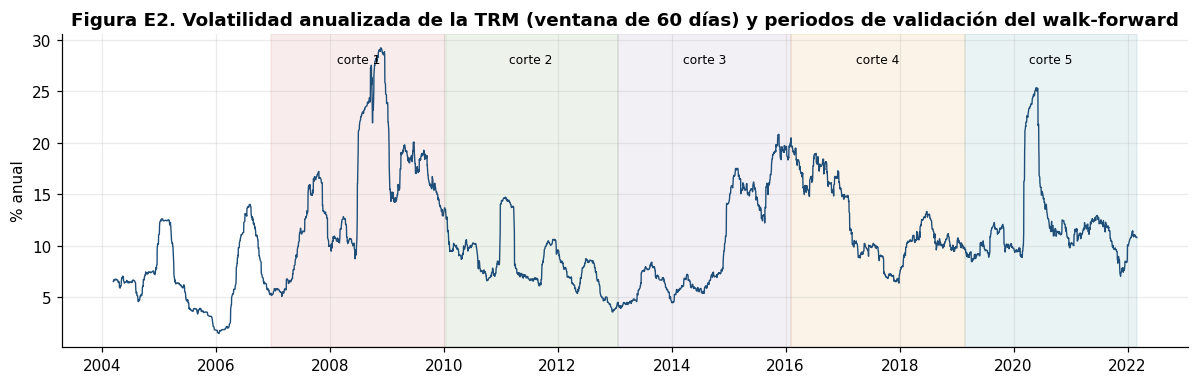

In [4]:
vol60 = y.rolling(60).std() * np.sqrt(252) * 100
ac = pd.DataFrame({"retornos": [y.autocorr(k) for k in (1, 5, 10)],
                   "retornos al cuadrado": [(y ** 2).autocorr(k) for k in (1, 5, 10)]}, index=[1, 5, 10])
ac.index.name = "rezago"
display(ac)

cortes = cortes_walk_forward(len(dev))
tcortes = tabla_cortes(dev["fecha"], cortes)
tcortes["volatilidad_anual_pct"] = [100 * y.iloc[va].std() * np.sqrt(252) for _, va in cortes]
tcortes["rmse_sin_cambio_pesos"] = [np.sqrt(np.mean((dev["trm_sig"].iloc[va] - dev["trm"].iloc[va]) ** 2)) for _, va in cortes]
guardar_tabla(tcortes, "tabE3_cortes_volatilidad")
display(tcortes)

fig, eje = plt.subplots(figsize=(11, 3.6))
eje.plot(dev["fecha"], vol60, color=COLORES[0], lw=0.9)
for i, (_, va) in enumerate(cortes):
    eje.axvspan(dev["fecha"].iloc[va[0]], dev["fecha"].iloc[va[-1]], color=COLORES[i % 5 + 1], alpha=0.10)
    eje.text(dev["fecha"].iloc[va[len(va) // 2]], vol60.max() * 0.95, f"corte {i+1}", ha="center", fontsize=8)
eje.set(title="Figura E2. Volatilidad anualizada de la TRM (ventana de 60 días) y periodos de validación del walk-forward",
        ylabel="% anual")
fig.tight_layout(); guardar_figura(fig, "figE2_volatilidad"); plt.show()

**Conclusión E3.** La volatilidad **se agrupa**. La autocorrelación de los retornos al cuadrado (0,24; 0,21; 0,12 en los rezagos 1, 5 y 10) supera mucho a la de los retornos: los días turbulentos vienen seguidos. La volatilidad anual va de menos del 5 % (2006, 2013) a más del 25 % (crisis de 2008 y marzo de 2020). Los 5 periodos de validación del walk-forward reciben dificultades muy distintas: el corte 2 (2010–2013) tiene **8,5 %** de volatilidad y un RMSE "sin cambio" de **10 pesos**, y el corte 5 (2019–2022, COVID) **12,6 %** y **29 pesos**. Parte de esa diferencia en pesos se debe también al nivel de la TRM, que en el corte 5 ronda los 3.500 pesos.

**→ Consecuencia:** el error de **cualquier** modelo va a variar mucho entre cortes por el periodo, no por el modelo. Por eso los modelos se comparan **dentro de cada corte**, en el mismo periodo, y se reporta la variabilidad entre cortes (rúbrica 7.4).

## E4. ¿Hay memoria en la TRM? ¿Sirven los rezagos 1, 5 y 10 de la Entrega 1?
La línea base prometida es una regresión lineal sobre los rezagos 1, 5 y 10 de la TRM. Su capacidad depende de la autocorrelación de los retornos. Hay además una razón mecánica para esperar autocorrelación en el rezago 1: la TRM es un **promedio** de las operaciones del día, y los promedios de una serie que se mueve a lo largo del día quedan correlacionados entre días consecutivos (efecto Working, 1960).

,acf,pacf,banda_95
rezago,,,
1,0.1655,0.1655,0.0298
2,0.0247,-0.0028,0.0298
3,-0.0265,-0.0310,0.0298
5,-0.0096,-0.0071,0.0298
10,0.0297,0.0281,0.0298


Rezagos con autocorrelación fuera de la banda de 95 %: [1]


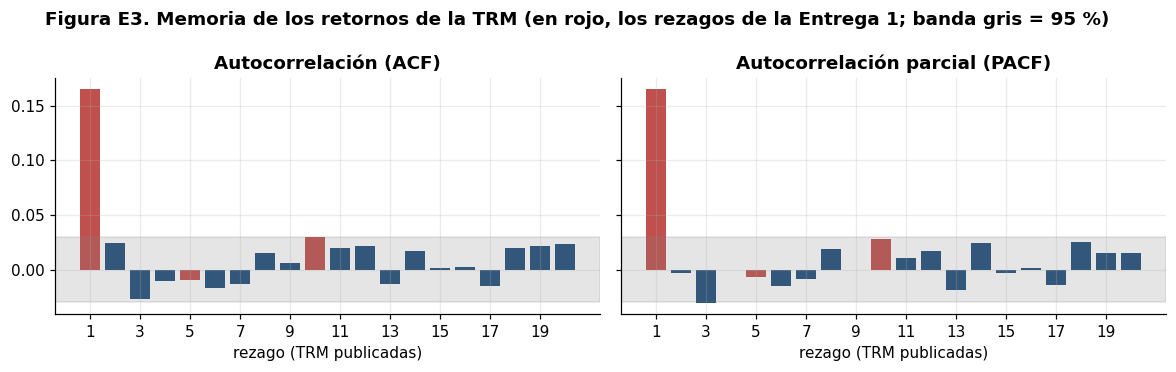

In [5]:
acf_tab = acf_con_banda(y)
guardar_tabla(acf_tab, "tabE4_autocorrelacion")
display(acf_tab.loc[[1, 2, 3, 5, 10]])
fuera = acf_tab.index[acf_tab["acf"].abs() > acf_tab["banda_95"]].tolist()
print(f"Rezagos con autocorrelación fuera de la banda de 95 %: {fuera}")

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for eje, col, tit in zip(ejes, ["acf", "pacf"], ["Autocorrelación (ACF)", "Autocorrelación parcial (PACF)"]):
    colores = [COLORES[1] if k in (1, 5, 10) else COLORES[0] for k in acf_tab.index]
    eje.bar(acf_tab.index, acf_tab[col], color=colores)
    eje.axhspan(-acf_tab["banda_95"].iloc[0], acf_tab["banda_95"].iloc[0], color="grey", alpha=0.2)
    eje.set(title=tit, xlabel="rezago (TRM publicadas)", xticks=range(1, 21, 2))
fig.suptitle("Figura E3. Memoria de los retornos de la TRM (en rojo, los rezagos de la Entrega 1; banda gris = 95 %)",
             fontweight="bold")
fig.tight_layout(); guardar_figura(fig, "figE3_autocorrelacion"); plt.show()

**Conclusión E4.** Hay **memoria de un día y nada más**. La autocorrelación del rezago 1 es **0,166** (IC 95 %: ±0,030), muy por fuera de la banda, y la parcial confirma que el efecto es directo. **Ningún otro rezago sale de la banda:** el rezago 5 es −0,010 y el 10 es 0,030, en el borde. Es lo que predice el efecto de promedio (Working): la TRM es un promedio del día, y eso induce autocorrelación positiva de un solo rezago.

**→ Consecuencia para la línea base de la Entrega 1:** de sus tres rezagos, solo el de 1 día tiene señal. Se espera que la regresión lineal alcance un R² cercano a ρ₁² ≈ **0,027**, y que los rezagos 5 y 10 aporten ruido de estimación más que información. No se quitan: son los prometidos, y el resultado lo dirá.

## E5. ¿Cada variable se relaciona con el objetivo como dice la teoría?
Signos esperados (Entrega 1): **Brent −** (más petróleo, más dólares entrando, peso más fuerte), **DXY +** (dólar global fuerte, peso más débil) y **diferencial −** (tasas locales altas atraen capital). Se reportan Pearson con IC 95 %, Spearman (robusto a extremos) y la **media del objetivo por decil** de cada variable, que muestra la forma de la relación.

,pearson,ic95_inf,ic95_sup,spearman,signo_esperado,significativa_95,coincide_con_teoria
r_trm_l1,0.1655,0.1363,0.1943,0.1768,+,True,sí
r_trm_l5,-0.0096,-0.0394,0.0203,-0.0135,?,False,—
r_trm_l10,0.0297,-0.0001,0.0595,0.0287,?,False,—
r_brent,-0.0565,-0.0862,-0.0267,-0.0566,−,True,sí
r_dxy,0.0937,0.0641,0.1232,0.1005,+,True,sí
dif_tasas,0.0084,-0.0214,0.0382,-0.0076,−,False,no significativa


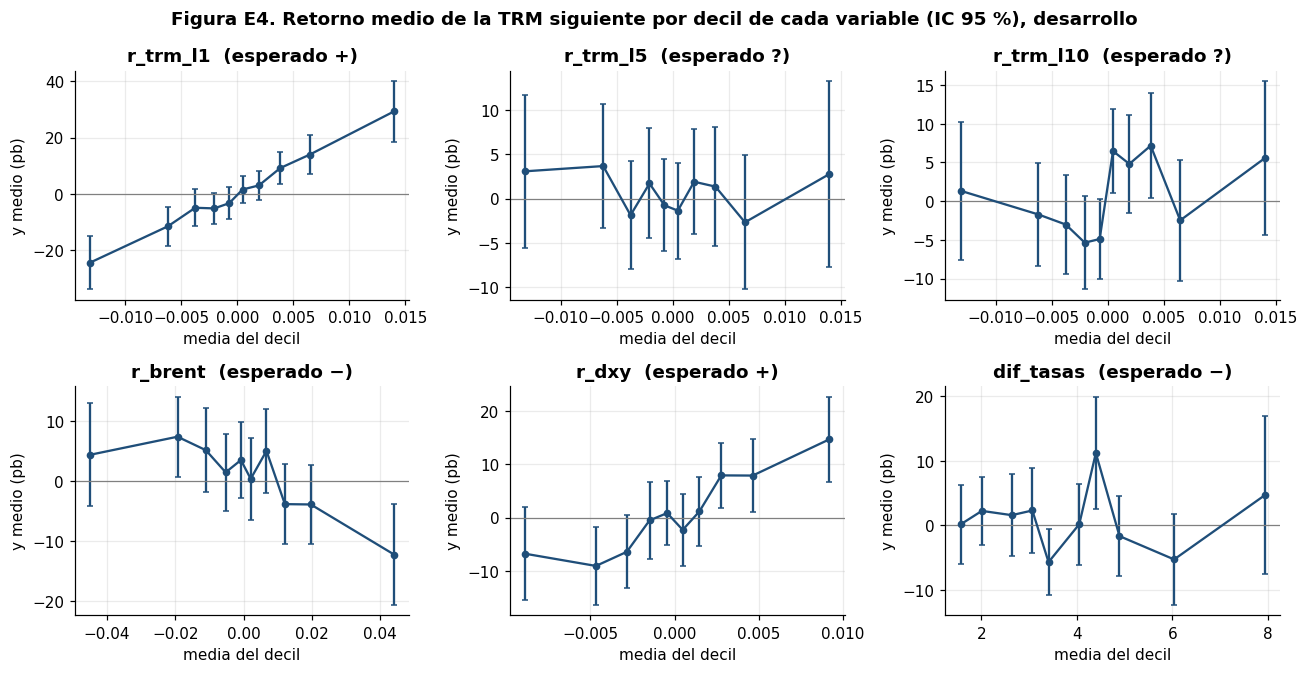

In [6]:
esperado = {"r_trm_l1": "+", "r_trm_l5": "?", "r_trm_l10": "?", "r_brent": "−", "r_dxy": "+", "dif_tasas": "−"}
e5 = pd.DataFrame({v: correlacion_con_ic(dev[v], y) for v in cfg.VARS_TODAS}).T
e5["signo_esperado"] = pd.Series(esperado)
e5["significativa_95"] = (e5["ic95_inf"] > 0) | (e5["ic95_sup"] < 0)
e5["coincide_con_teoria"] = np.where(e5["signo_esperado"] == "?", "—",
    np.where(~e5["significativa_95"], "no significativa",
    np.where(np.sign(e5["pearson"]) == e5["signo_esperado"].map({"+": 1, "−": -1}), "sí", "no")))
guardar_tabla(e5, "tabE5_correlaciones")
display(e5)

fig, ejes = plt.subplots(2, 3, figsize=(12, 6.2))
for eje, v in zip(ejes.ravel(), cfg.VARS_TODAS):
    d = medias_por_decil(dev[v], y)
    eje.errorbar(d["x_media"], 1e4 * d["y_media"], yerr=1.96e4 * d["y_se"], fmt="o-", color=COLORES[0], ms=4, capsize=2)
    eje.axhline(0, color="grey", lw=0.8)
    eje.set(title=f"{v}  (esperado {esperado[v]})", xlabel="media del decil", ylabel="y medio (pb)")
fig.suptitle("Figura E4. Retorno medio de la TRM siguiente por decil de cada variable (IC 95 %), desarrollo",
             fontweight="bold")
fig.tight_layout(); guardar_figura(fig, "figE4_deciles"); plt.show()

**Conclusión E5.** Las relaciones van en la dirección que dice la teoría, pero son **pequeñas**:
- **`r_trm_l1`:** +0,166, la más fuerte.
- **`r_dxy`:** **+0,094** (IC 95 %: 0,064 a 0,123), como se esperaba: un dólar global más fuerte sube la TRM siguiente.
- **`r_brent`:** **−0,057** (IC 95 %: −0,086 a −0,027), también como se esperaba: más petróleo, peso más fuerte.
- **`dif_tasas`:** **no se relaciona** con el retorno diario (0,008; IC 95 %: −0,021 a 0,038).

Pearson y Spearman coinciden, así que las relaciones no dependen de unos pocos extremos. La Figura E4 muestra relaciones **monótonas y aproximadamente lineales** en `r_trm_l1`, `r_dxy` y `r_brent`, y planas, dentro del ruido, en `r_trm_l5`, `r_trm_l10` y `dif_tasas`.

**→ Consecuencia:** de las tres variables macro, **dos tienen señal**, del orden de 0,06 a 0,09 de correlación. Si los modelos detectan algo, SHAP debería mostrar `r_dxy` con efecto positivo y `r_brent` negativo. Si no los muestra, sería una señal de sobreajuste.

## E6. ¿Esas relaciones son estables en el tiempo?
Una relación que cambia de signo entre periodos no se puede aprender del pasado y usar en el futuro. Se calcula la correlación móvil de 250 días (un año hábil) y la correlación por año calendario.

,pct_ventanas_con_signo_esperado,min,max
r_trm_l1,99.8035,-0.0362,0.3794
r_brent,64.0874,-0.2987,0.1227
r_dxy,95.0135,-0.1552,0.2684


anio,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
r_trm_l1,0.1900,0.2200,0.0800,0.2800,0.1000,0.0500,0.2400,0.1900,0.2200,0.2100,0.1200,0.3600,0.2200,0.2000,0.1100,0.1700,0.2000,0.0600,0.1800,0.0400
r_brent,0.1700,0.0300,-0.0400,0.0400,0.0500,0.0100,-0.0300,-0.0100,-0.0800,-0.0100,0.0300,-0.2100,-0.2500,-0.0600,-0.1100,-0.0500,0.0700,-0.1000,-0.1100,-0.1500
r_dxy,-0.3300,0.0400,0.1600,0.1400,0.0400,-0.0600,0.1400,0.1700,0.1400,0.1300,0.1000,0.0400,0.0900,0.2400,0.0600,0.2100,0.2500,0.0600,0.0500,0.1000
dif_tasas,-0.2200,0.0700,0.0100,-0.1000,0.0800,0.1000,0.0600,-0.0200,0.0900,0.1100,0.0400,0.2000,0.0400,0.0400,0.0100,-0.1100,-0.0600,0.0700,0.0700,0.1200


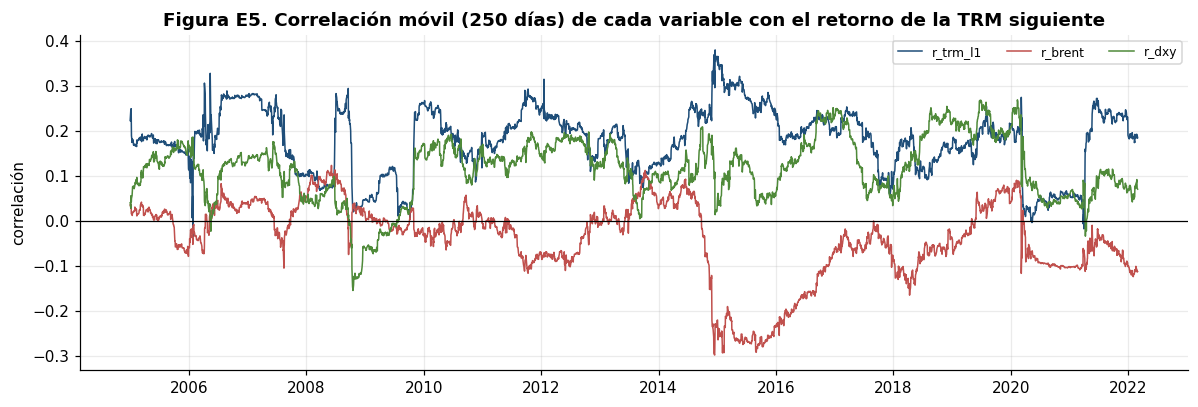

In [7]:
movil = pd.DataFrame({v: dev[v].rolling(250).corr(y) for v in ["r_trm_l1", "r_brent", "r_dxy"]})
movil["fecha"] = dev["fecha"]
estab = pd.DataFrame({
    v: {"pct_ventanas_con_signo_esperado": 100 * (np.sign(movil[v].dropna()) == s).mean(),
        "min": movil[v].min(), "max": movil[v].max()}
    for v, s in [("r_trm_l1", 1), ("r_brent", -1), ("r_dxy", 1)]}).T
anual = dev.assign(anio=dev["fecha"].dt.year).groupby("anio").apply(
    lambda g: pd.Series({v: np.corrcoef(g[v], g["y"])[0, 1] for v in ["r_trm_l1", "r_brent", "r_dxy", "dif_tasas"]}),
    include_groups=False)
guardar_tabla(estab, "tabE6_estabilidad"); guardar_tabla(anual, "tabE6b_correlacion_anual")
display(estab)
display(anual.T.round(2))

fig, eje = plt.subplots(figsize=(11, 3.8))
for v, c in zip(["r_trm_l1", "r_brent", "r_dxy"], COLORES):
    eje.plot(movil["fecha"], movil[v], color=c, lw=1, label=v)
eje.axhline(0, color="black", lw=0.8)
eje.set(title="Figura E5. Correlación móvil (250 días) de cada variable con el retorno de la TRM siguiente", ylabel="correlación")
eje.legend(ncol=3, fontsize=8)
fig.tight_layout(); guardar_figura(fig, "figE5_correlacion_movil"); plt.show()

**Conclusión E6.** La estabilidad es **muy distinta entre variables**:
- **`r_trm_l1`:** conserva el signo positivo en el **99,8 %** de las ventanas de un año. La memoria de la TRM es un rasgo estable.
- **`r_dxy`:** positivo en el **95 %** de las ventanas. Solo se invierte en la crisis de 2008–2009.
- **`r_brent`:** negativo en solo el **64 %** de las ventanas. Su relación aparece con fuerza en los **choques petroleros**: −0,30 en la caída de 2014–2016 y alrededor de −0,10 desde 2020. Entre 2003 y 2009 es casi nula o positiva.
- **`dif_tasas`:** su correlación anual cambia de signo de un año a otro, entre −0,22 y +0,20. No hay una relación estable que aprender.

**→ Consecuencia:** el aporte del Brent **depende del régimen**. Un modelo entrenado en un periodo sin choques petroleros no aprenderá a usarlo, y uno entrenado con esos choques sí. Esto anticipa que **el aporte de las variables macro va a variar entre cortes del walk-forward**.

## E7. ¿Qué papel tiene el diferencial de tasas?
El diferencial solo cambia cuando el Banrep o la Fed mueven su tasa, así que día a día es casi constante: difícilmente explica el movimiento **diario** de la TRM. Además, el Banrep puede **reaccionar** a la TRM (subir tasas cuando el peso se devalúa), lo que invertiría la dirección causal. Se revisa: cuántos días cambia, si su nivel se relaciona con el retorno siguiente y si una subida pasada de la TRM precede a subidas del diferencial.

In [8]:
cambia = dev["dif_tasas"].diff().ne(0)
trm_lvl = dev["trm"]
subida_trm_60 = np.log(trm_lvl / trm_lvl.shift(60))                      # cuánto subió la TRM en los 60 días previos
cambio_dif_futuro = {h: dev["dif_tasas"].shift(-h) - dev["dif_tasas"] for h in (20, 60, 120)}
e7 = pd.Series({
    "pct_dias_en_que_cambia_el_diferencial": 100 * cambia.mean(),
    "corr_nivel_diferencial_vs_y": np.corrcoef(dev["dif_tasas"], y)[0, 1],
    **{f"corr_subida_TRM_60d_vs_cambio_diferencial_{h}d_despues": subida_trm_60.corr(c) for h, c in cambio_dif_futuro.items()},
}, name="valor")
guardar_tabla(e7.to_frame(), "tabE7_tasas")
display(e7.to_frame())

,valor
pct_dias_en_que_cambia_el_diferencial,46.5509
corr_nivel_diferencial_vs_y,0.0084
corr_subida_TRM_60d_vs_cambio_diferencial_20d_despues,0.0351
corr_subida_TRM_60d_vs_cambio_diferencial_60d_despues,-0.0170
corr_subida_TRM_60d_vs_cambio_diferencial_120d_despues,-0.0721


**Conclusión E7.** El diferencial cambia en el 47 % de los días, casi siempre por el ruido diario de la DFF y no por decisiones de política. Su nivel **no se relaciona** con el retorno siguiente (0,008). Tampoco hay evidencia de **causalidad inversa** a estos horizontes: la subida de la TRM en 60 días casi no se relaciona con el cambio posterior del diferencial a 20, 60 o 120 días (entre −0,07 y 0,04).

**→ Consecuencia:** el diferencial de tasas, prometido en la Entrega 1 por su argumento económico (carry), **no aporta información para el horizonte de un día**. El carry actúa en meses, no en días. Se mantiene en el modelo por el contrato con la Entrega 1, y se espera que su importancia en SHAP sea mínima o que el modelo lo use para identificar periodos, lo que sería sobreajuste.

## E8. ¿Las variables se repiten entre sí?
Si dos variables miden lo mismo, un modelo de árboles puede repartir o concentrar el mérito entre ellas de forma arbitraria, y la importancia (SHAP) se lee distinto. Se revisan la matriz de correlaciones y el VIF (mayor que 5 indica redundancia).

In [9]:
corr = dev[cfg.VARS_TODAS].corr()
e8 = vif(dev[cfg.VARS_TODAS]).to_frame()
e8["max_corr_abs_con_otra"] = corr.where(~np.eye(len(corr), dtype=bool)).abs().max()
guardar_tabla(corr, "tabE8_correlaciones_variables"); guardar_tabla(e8, "tabE8b_vif")
display(corr.round(3))
display(e8)

,r_trm_l1,r_trm_l5,r_trm_l10,r_brent,r_dxy,dif_tasas
r_trm_l1,1.0000,-0.0100,0.0070,-0.2920,0.2460,0.0030
r_trm_l5,-0.0100,1.0000,-0.0100,-0.0080,0.0370,0.0050
r_trm_l10,0.0070,-0.0100,1.0000,-0.0230,0.0170,0.0090
r_brent,-0.2920,-0.0080,-0.0230,1.0000,-0.1410,-0.0190
r_dxy,0.2460,0.0370,0.0170,-0.1410,1.0000,0.0170
dif_tasas,0.0030,0.0050,0.0090,-0.0190,0.0170,1.0000


,VIF,max_corr_abs_con_otra
r_trm_l1,1.1477,0.2924
r_trm_l5,1.0020,0.0367
r_trm_l10,1.0009,0.0228
r_brent,1.1006,0.2924
r_dxy,1.0725,0.2460
dif_tasas,1.0007,0.0194


**Conclusión E8.** **No hay redundancia:** todos los VIF están por debajo de 1,15. La correlación más alta entre variables es la de `r_trm_l1` con `r_brent` (**−0,29**) y con `r_dxy` (**+0,25**). Tiene lógica, porque la TRM de hoy ya incorpora en parte el movimiento del petróleo y del dólar de ayer.

**→ Consecuencia:** las importancias se pueden leer por separado, sin el problema de mérito repartido. Parte de la señal del Brent y del DXY ya está contenida en la propia TRM, así que su aporte **adicional** será menor que su correlación simple.

## E9. ¿Hay relaciones no lineales que el boosting pueda aprovechar?
Es la pregunta que decide si tiene sentido esperar que LightGBM, CatBoost o XGBoost le ganen a la línea base lineal. Hay que separar dos cosas:
- **Dependencia en la media**, que es la que sirve para predecir el retorno. Se mide con el **η² por deciles**: la fracción de la varianza de *y* que explican las medias por decil de la variable, sin suponer una recta. Si η² es parecido al r² lineal, la relación en la media es lineal y un árbol no tiene nada extra que capturar. Se descuenta el η² esperado por azar con 10 grupos, (10 − 1)/(n − 1) ≈ 0,002.
- **Dependencia de cualquier tipo**, incluida la de la volatilidad. Se mide con la **información mutua** (MI) con *y* y con |*y*|. Si la MI con |*y*| es tan alta como con *y*, la variable anticipa **cuánto** se va a mover la TRM, pero no **hacia dónde**. Eso no mejora una predicción puntual con error cuadrático.

Como referencia de cuánto se puede predecir, se calcula el R² **dentro de muestra** de la regresión lineal: es un techo optimista, porque se evalúa sobre los mismos datos con que se ajusta.

In [10]:
mi_y = mutual_info_regression(dev[cfg.VARS_TODAS], y, n_neighbors=5, random_state=cfg.SEMILLA)
mi_abs = mutual_info_regression(dev[cfg.VARS_TODAS], y.abs(), n_neighbors=5, random_state=cfg.SEMILLA)

def eta2_deciles(x, y, q=10):
    g = pd.qcut(x.rank(method="first"), q, labels=False)      # rank: deciles del mismo tamaño aunque haya empates
    medias = y.groupby(g).transform("mean")
    return ((medias - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum()

azar = 9 / (len(y) - 1)
e9 = pd.DataFrame({
    "r2_lineal": e5.loc[cfg.VARS_TODAS, "pearson"] ** 2,
    "eta2_deciles_menos_azar": [eta2_deciles(dev[v], y) - azar for v in cfg.VARS_TODAS],
    "MI_con_y": mi_y, "MI_con_abs_y": mi_abs,
}, index=cfg.VARS_TODAS)
guardar_tabla(e9, "tabE9_no_linealidad")
display(e9)

techo = pd.Series({
    "R2_dentro_muestra_lineal_solo_TRM": LinearRegression().fit(dev[cfg.VARS_TRM], y).score(dev[cfg.VARS_TRM], y),
    "R2_dentro_muestra_lineal_TRM_macro": LinearRegression().fit(dev[cfg.VARS_TODAS], y).score(dev[cfg.VARS_TODAS], y),
    "rho1_al_cuadrado": acf_tab.loc[1, "acf"] ** 2,
}, name="valor")
guardar_tabla(techo.to_frame(), "tabE9b_techo_lineal")
display(techo.to_frame())

,r2_lineal,eta2_deciles_menos_azar,MI_con_y,MI_con_abs_y
r_trm_l1,0.0274,0.0321,0.0682,0.0475
r_trm_l5,0.0001,-0.0013,0.0136,0.0170
r_trm_l10,0.0009,0.0017,0.0164,0.0151
r_brent,0.0032,0.0035,0.0000,0.0047
r_dxy,0.0088,0.0070,0.0000,0.0000
dif_tasas,0.0001,0.0013,0.0710,0.0589


,valor
R2_dentro_muestra_lineal_solo_TRM,0.0283
R2_dentro_muestra_lineal_TRM_macro,0.0313
rho1_al_cuadrado,0.0274


**Conclusión E9, la más importante para el proyecto.** En las seis variables, el **η² por deciles es prácticamente igual al r² lineal**. En `r_trm_l1`, 0,032 frente a 0,027; en `r_dxy`, 0,007 frente a 0,009; en el resto, menos de 0,004. La relación con la **media** del retorno es esencialmente lineal: un modelo que puede dibujar cualquier forma no encuentra más que una recta. En cambio, la información mutua con |*y*| es tan alta como con *y* (por ejemplo, 0,048 frente a 0,068 en `r_trm_l1`). Lo que las variables anticipan de forma no lineal es **cuánto** se va a mover la TRM, su volatilidad, y **no hacia dónde**. Eso explica también la información mutua alta del diferencial: identifica el periodo, y cada periodo tiene su volatilidad. El R² dentro de muestra de la regresión lineal es **0,028** solo con la TRM y **0,031** con las macro: incluso mirando los mismos datos, las macro suman apenas **0,003**.

**→ Consecuencia:** hay muy poco espacio para que el boosting le gane a la línea base. **Una de las hipótesis centrales del proyecto es que no lo hará de forma apreciable**, y que cualquier ventaja estará por debajo de 0,005 de R². Si un boosting muestra mucho más en validación, hay que sospechar de sobreajuste. Este resultado responde **por adelantado** a la pregunta "¿por qué el método del artículo no rinde aquí?": en forex, la ventaja de los árboles viene de relaciones no lineales en la media, y en la TRM diaria no las hay.

## E10. ¿Cambia todo esto por régimen histórico?
Se divide el desarrollo en siete regímenes con hechos conocidos y se mide en cada uno la volatilidad, la memoria (autocorrelación de rezago 1) y la relación con el Brent y el DXY. Si estas cantidades cambian mucho entre regímenes, un modelo entrenado en unos periodos tendrá un desempeño distinto en otros.

In [11]:
regimenes = [("Apreciación", "2003-12-01", "2008-08-31"), ("Crisis financiera", "2008-09-01", "2009-12-31"),
             ("Auge petrolero", "2010-01-01", "2014-06-30"), ("Caída del petróleo", "2014-07-01", "2016-12-31"),
             ("Estabilidad", "2017-01-01", "2020-02-29"), ("COVID", "2020-03-01", "2020-12-31"),
             ("Recuperación", "2021-01-01", "2022-03-01")]
filas = []
for nombre, a, b in regimenes:
    g = dev[(dev["fecha"] >= a) & (dev["fecha"] <= b)]
    filas.append({"regimen": nombre, "desde": a, "hasta": b, "dias": len(g),
                  "retorno_anual_pct": 100 * g["y"].mean() * 252,
                  "volatilidad_anual_pct": 100 * g["y"].std() * np.sqrt(252),
                  "autocorr_rezago1": g["y"].autocorr(1),
                  "corr_brent": np.corrcoef(g["r_brent"], g["y"])[0, 1],
                  "corr_dxy": np.corrcoef(g["r_dxy"], g["y"])[0, 1]})
e10 = pd.DataFrame(filas).set_index("regimen")
assert e10["dias"].sum() == len(dev)
guardar_tabla(e10, "tabE10_regimenes")
display(e10)

,desde,hasta,dias,retorno_anual_pct,volatilidad_anual_pct,autocorr_rezago1,corr_brent,corr_dxy
regimen,,,,,,,,
Apreciación,2003-12-01,2008-08-31,1119,-7.8036,10.2940,0.2338,0.0224,0.0692
Crisis financiera,2008-09-01,2009-12-31,316,1.8403,19.4272,0.0393,-0.0140,0.0255
Auge petrolero,2010-01-01,2014-06-30,1067,-1.8944,7.8467,0.1930,-0.0206,0.1364
Caída del petróleo,2014-07-01,2016-12-31,594,19.8882,15.8461,0.2299,-0.1626,0.1431
Estabilidad,2017-01-01,2020-02-29,749,5.5162,9.9902,0.1688,-0.0243,0.1644
COVID,2020-03-01,2020-12-31,199,-3.3387,16.7762,0.0371,-0.1040,0.0590
Recuperación,2021-01-01,2022-03-01,276,12.0086,10.8429,0.1709,-0.1193,0.0534


**Conclusión E10.** Todo cambia por régimen:
- **Volatilidad:** va del 7,8 % (auge petrolero) al 19,4 % (crisis de 2008).
- **La memoria desaparece en las crisis.** La autocorrelación del rezago 1 cae de 0,17–0,23 en periodos normales a **0,04 en la crisis de 2008 y en el COVID**.
- **El Brent pesa en los choques petroleros:** correlación de −0,16 en la caída de 2014–2016, −0,10 en el COVID y −0,12 en la recuperación, y casi cero en los demás periodos.
- **El DXY es más estable,** entre 0,03 y 0,16.

**→ Consecuencia:** la línea base, que depende de la memoria, va a fallar **justo cuando más importa**, en los periodos turbulentos. Las macro, en particular el Brent, podrían ayudar precisamente en los choques petroleros. Si el periodo de evaluación incluye choques de ese tipo, las macro tendrían más oportunidad de aportar que en el promedio del desarrollo.

## Síntesis: qué esperamos de los modelos (escrito antes de entrenarlos)

**Lo que el EDA establece:**
1. **Hay que modelar el retorno, no el nivel.** Los niveles no son estacionarios y su rango cambia con el tiempo dentro del propio desarrollo (E1).
2. **La TRM diaria es poco predecible, pero no es ruido puro.** La única señal fuerte es la memoria de un día, alrededor de 0,17, explicada por el efecto de promedio (E4). El techo lineal dentro de muestra es un R² de alrededor de **0,03** (E9).
3. **Las variables macro tienen señal pequeña y la que dice la teoría:** DXY positivo, Brent negativo. El diferencial no aporta a un día (E5, E7). Además esa señal es **inestable**: el Brent solo pesa en los choques petroleros (E6, E10).
4. **La relación en la media es lineal.** Lo no lineal está en la volatilidad, que no sirve para una predicción puntual (E9).
5. **El error depende del periodo y de pocos días extremos** (E2, E3, E10).

**Hipótesis que se contrastan en los notebooks 05 y 06:**

| # | Hipótesis | Se contrasta con |
|---|---|---|
| H1 | La línea base lineal logra un R² sobre retornos pequeño y positivo, cercano a 0,03, y le gana a predecir "sin cambio" en la mayoría de los cortes | Tabla 5 (validación) |
| H2 | Los tres boosting **no superan de forma apreciable** a la línea base: diferencias en R² menores a 0,005 y dentro de la variabilidad entre cortes | Tabla 5 y test |
| H3 | Las variables macro aportan **poco y de forma inestable**, con mejoras en unos cortes y no en otros, más en los periodos de choque petrolero | Tabla 6 / Figura 4 |
| H4 | El error es mayor en los cortes y periodos turbulentos (corte 1 con 2008, corte 5 con COVID; en el test, sus periodos más volátiles) | Tabla 5 por corte y Figura 6 |
| H5 | SHAP muestra `r_trm_l1` como la variable dominante, `r_dxy` con efecto positivo, `r_brent` negativo y `dif_tasas`, `r_trm_l5` y `r_trm_l10` con importancia mínima | Figura 5 |
| H6 | El método del artículo en niveles falla fuera del rango del desarrollo: el techo de extrapolación en 4.154 | Notebook 04, Figura 3 |

Si los resultados contradicen alguna hipótesis, se explicará por qué. Si la confirman, el resultado negativo, que las macro aporten poco, **queda fundamentado de antemano** y no es una conclusión improvisada.